# Практическая часть: EDA и Pipeline для банковского депозита

**Автор блока:** Ислам — исследование данных, обработка пропусков, `ColumnTransformer` и `Pipeline` без утечки данных.

## Цель
Понять структуру кампании прямого маркетинга банка и подготовить воспроизводимый конвейер обработки признаков для предсказания подписки на срочный депозит (`y`). Метрики и выбор рабочего порога остаются в блоке сравнения моделей команды.

**Данные:** `bank-additional-full.csv`, разделитель `;`. Признак `duration` исключается: длительность звонка известна только после разговора и не подходит для решения до звонка.

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid", palette="deep")
DATA_PATH = Path("bank-additional-full.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError("Положите bank-additional-full.csv рядом с этим ноутбуком")

df = pd.read_csv(DATA_PATH, sep=";")
print(f"Размер таблицы: {df.shape[0]:,} строк × {df.shape[1]} столбцов")
display(df.head())

Размер таблицы: 41,188 строк × 21 столбцов


   age        job  marital    education  default housing loan    contact month day_of_week  duration  campaign  pdays  previous     poutcome  emp.var.rate  cons.price.idx  cons.conf.idx  euribor3m  nr.employed   y
0   56  housemaid  married     basic.4y       no      no   no  telephone   may         mon       261         1    999         0  nonexistent           1.1          93.994          -36.4      4.857       5191.0  no
1   57   services  married  high.school  unknown      no   no  telephone   may         mon       149         1    999         0  nonexistent           1.1          93.994          -36.4      4.857       5191.0  no
2   37   services  married  high.school       no     yes   no  telephone   may         mon       226         1    999         0  nonexistent           1.1          93.994          -36.4      4.857       5191.0  no
3   40     admin.  married     basic.6y       no      no   no  telephone   may         mon       151         1    999         0  nonexistent    

## 1. Первичный обзор

В датасете одна строка соответствует контакту с клиентом. Целевой столбец `y` показывает, оформил ли клиент срочный депозит. Сначала проверяем типы, дубликаты, пропуски и баланс целевого класса.

In [1]:
print("Типы данных:")
display(df.dtypes.astype(str).rename("Тип").to_frame())
print(f"Полных дубликатов строк: {df.duplicated().sum():,}")
print("Пустые значения (NaN) до обработки:")
display(df.isna().sum().loc[lambda x: x.gt(0)].rename("Количество").to_frame())
print("Баланс целевого класса:")
target_summary = df["y"].value_counts().rename_axis("Результат").to_frame("Количество")
target_summary["Доля, %"] = (target_summary["Количество"] / len(df) * 100).round(2)
display(target_summary)

Типы данных:
Полных дубликатов строк: 12
Пустые значения (NaN) до обработки:
Баланс целевого класса:


                    Тип
age               int64
job                 str
marital             str
education           str
default             str
housing             str
loan                str
contact             str
month               str
day_of_week         str
duration          int64
campaign          int64
pdays             int64
previous          int64
poutcome            str
emp.var.rate    float64
cons.price.idx  float64
cons.conf.idx   float64
euribor3m       float64
nr.employed     float64
y                   str

Empty DataFrame
Columns: [Количество]
Index: []

           Количество  Доля, %
Результат                     
no              36548    88.73
yes              4640    11.27

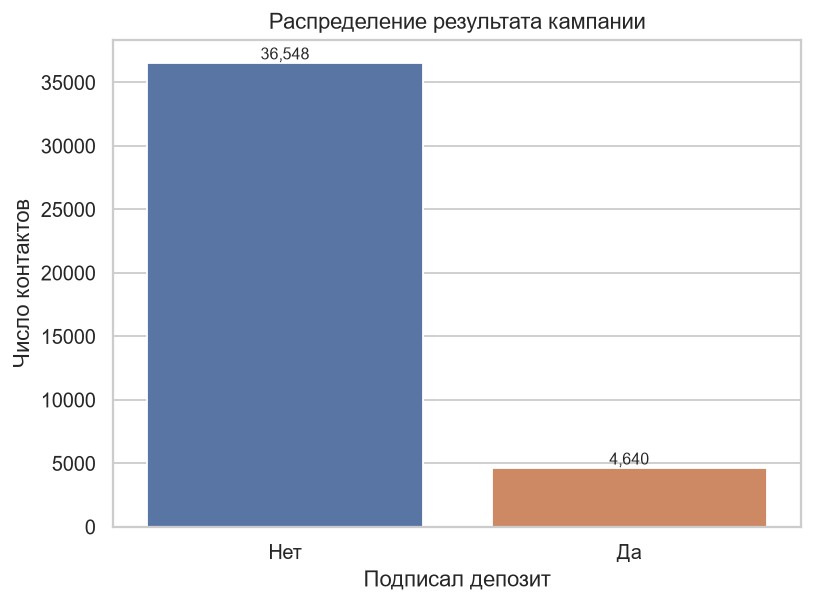

In [1]:
ax = sns.countplot(data=df, x="y", order=["no", "yes"], hue="y", legend=False)
ax.set(title="Распределение результата кампании", xlabel="Подписал депозит", ylabel="Число контактов")
ax.set_xticks([0, 1], ["Нет", "Да"])
for bar in ax.patches:
    ax.annotate(f"{int(bar.get_height()):,}", (bar.get_x() + bar.get_width()/2, bar.get_height()),
                ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

В данных **41 188** контактов; положительный класс `yes` заметно реже отрицательного. Поэтому accuracy в одиночку может скрывать слабое обнаружение потенциальных вкладчиков. Выбор метрик с учётом стоимости ошибок выполняется в командном блоке сравнения моделей.

## 2. Скрытые пропуски и особенности признаков

CSV не содержит пустых `NaN`, но категория `unknown` обозначает неизвестное значение. Посчитаем её по столбцам. Значение `pdays = 999` — специальный код «клиент ранее не контактировался», его нельзя автоматически считать обычным числовым значением или пропуском.

           Значений unknown
default                8597
education              1731
housing                 990
loan                    990
job                     330
marital                  80

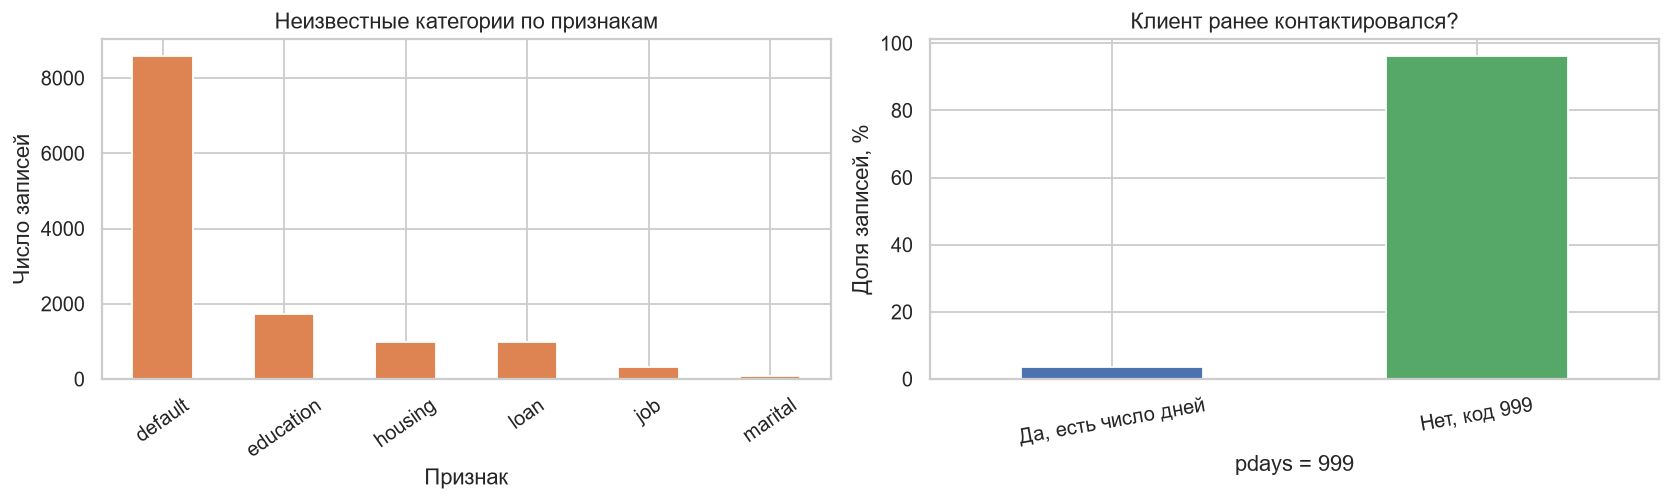

In [1]:
unknown_counts = df.select_dtypes(include=["object", "str"]).eq("unknown").sum()
unknown_counts = unknown_counts[unknown_counts.gt(0)].sort_values(ascending=False)
display(unknown_counts.rename("Значений unknown").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
if len(unknown_counts):
    unknown_counts.plot(kind="bar", ax=axes[0], color="#dd8452")
    axes[0].set(title="Неизвестные категории по признакам", xlabel="Признак", ylabel="Число записей")
    axes[0].tick_params(axis="x", rotation=35)
else:
    axes[0].text(.5, .5, "Значений unknown нет", ha="center", va="center")
    axes[0].set_axis_off()
(df["pdays"].eq(999).value_counts(normalize=True).sort_index() * 100).plot(
    kind="bar", ax=axes[1], color=["#4c72b0", "#55a868"])
axes[1].set(title="Клиент ранее контактировался?", xlabel="pdays = 999", ylabel="Доля записей, %")
axes[1].set_xticks([0, 1], ["Да, есть число дней", "Нет, код 999"])
axes[1].tick_params(axis="x", rotation=10)
plt.tight_layout()
plt.show()

В пайплайне `unknown` преобразуется в пропуск. Числовые пропуски заполняются медианой, категориальные — наиболее частой категорией. Параметры заполнения и масштабирования вычисляются только на train благодаря размещению обработчиков внутри `Pipeline`.

## 3. EDA числовых признаков и проверка утечки

`duration` удаляем до разделения: это постфактум-признак, который в реальном сценарии прогнозирования до звонка ещё неизвестен. Оставляем `pdays=999` как предоставленный датасетом специальный код, сохраняя его смысл в интерпретации.

Распределения числовых признаков (duration показан только для объяснения исключения):
duration исключается из признаков модели; его статистика здесь лишь иллюстрирует причину:


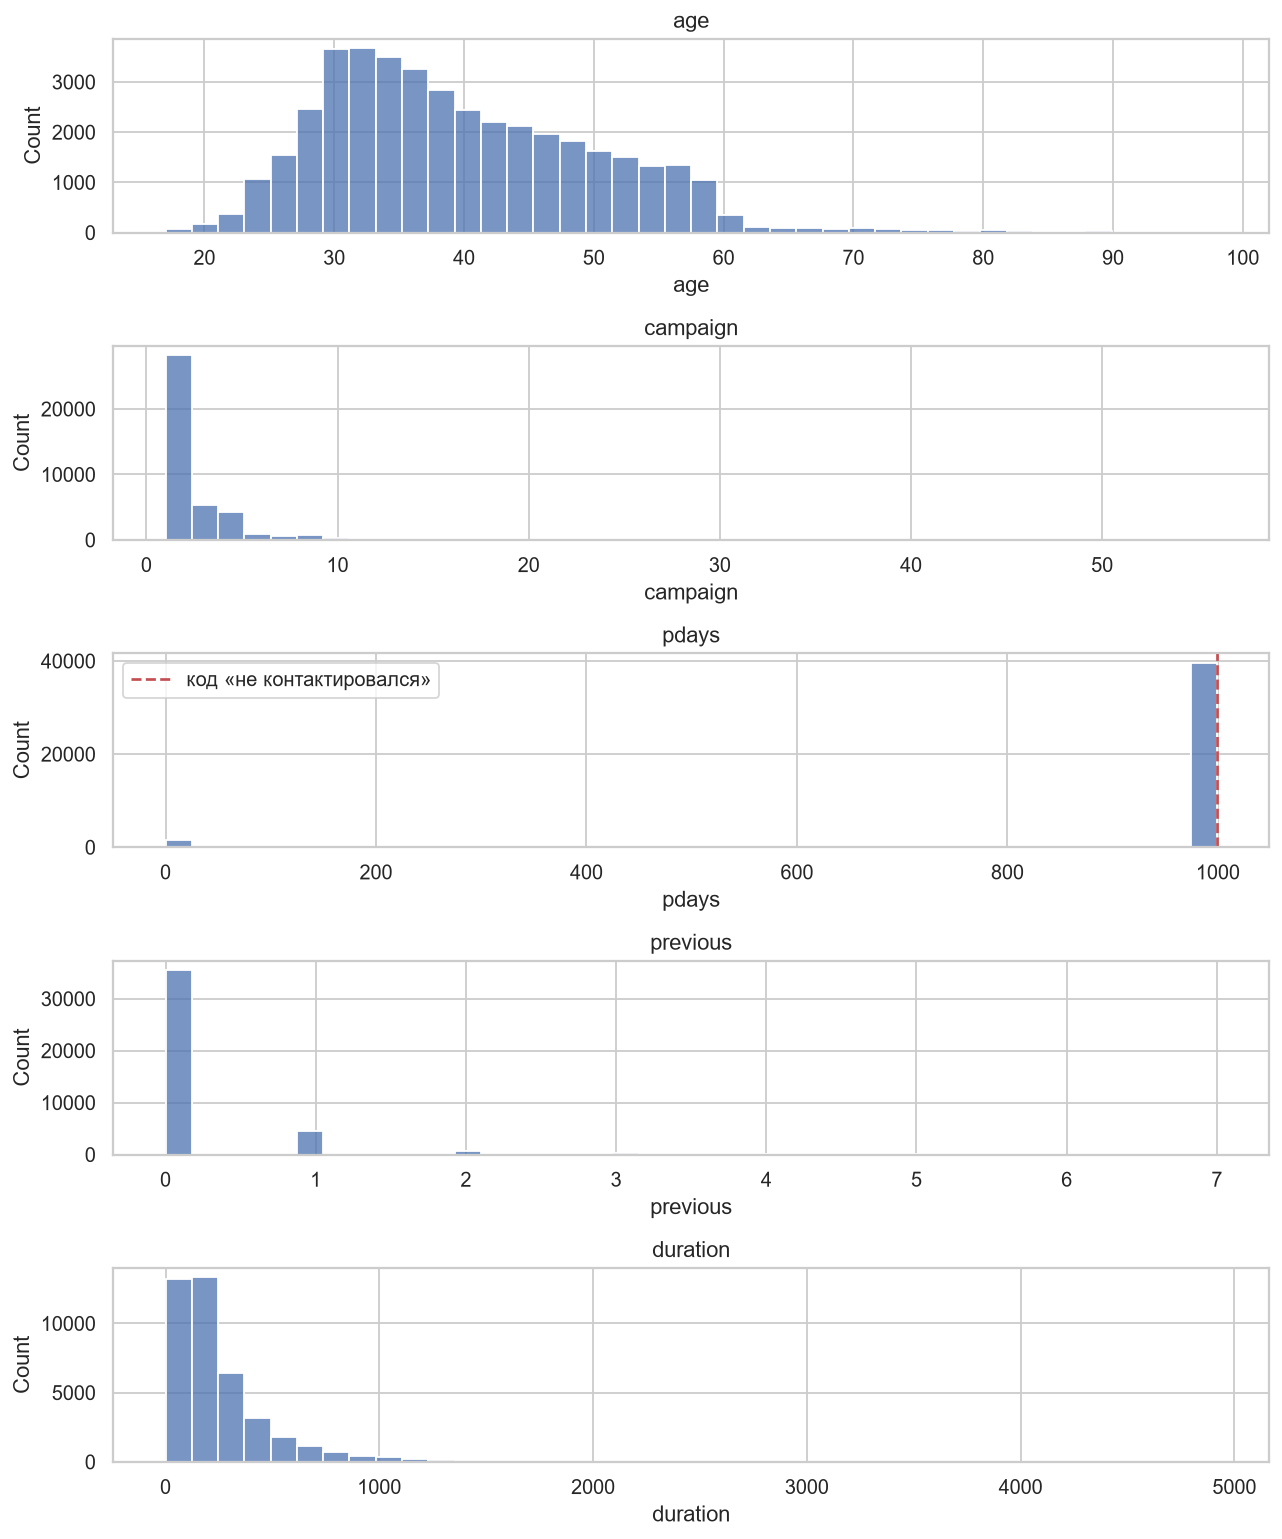

           duration
count  41188.000000
mean     258.285010
std      259.279249
min        0.000000
25%      102.000000
50%      180.000000
75%      319.000000
max     4918.000000

In [1]:
print("Распределения числовых признаков (duration показан только для объяснения исключения):")
num_for_plot = ["age", "campaign", "pdays", "previous", "duration"]
fig, axes = plt.subplots(len(num_for_plot), 1, figsize=(10, 12))
for ax, col in zip(axes, num_for_plot):
    sns.histplot(data=df, x=col, bins=40, ax=ax, color="#4c72b0")
    ax.set_title(col)
    if col == "pdays":
        ax.axvline(999, color="#c44e52", linestyle="--", label="код «не контактировался»")
        ax.legend()
plt.tight_layout()
plt.show()

print("duration исключается из признаков модели; его статистика здесь лишь иллюстрирует причину:")
display(df["duration"].describe().to_frame("duration"))

## 4. Разделение данных и построение конвейера

Разделяем данные стратифицированно (80% train / 20% test), чтобы доля `yes` сохранилась в обеих частях. Столбец `y` отделён от признаков; `duration` удалён. Ниже создаётся функция, которая принимает любую модель, поэтому коллеги смогут подставить Logistic Regression или вторую модель без копирования обработки.

In [1]:
TARGET = "y"
LEAKAGE_FEATURES = ["duration"]

# Скрытые пропуски превращаем в NaN до разбиения; правила заполнения
# будут обучаться только внутри Pipeline на тренировочной части.
model_df = df.replace("unknown", np.nan)
y = model_df[TARGET].map({"no": 0, "yes": 1})
X = model_df.drop(columns=[TARGET] + LEAKAGE_FEATURES)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

numeric_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = X_train.select_dtypes(exclude="number").columns.tolist()

print(f"Train: {X_train.shape[0]:,}; test: {X_test.shape[0]:,}")
print(f"Числовые признаки ({len(numeric_features)}): {numeric_features}")
print(f"Категориальные признаки ({len(categorical_features)}): {categorical_features}")
print(f"duration в X: {'duration' in X.columns}")
print(f"Доля yes — train: {y_train.mean():.3f}; test: {y_test.mean():.3f}")

Train: 32,950; test: 8,238
Числовые признаки (9): ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Категориальные признаки (10): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
duration в X: False
Доля yes — train: 0.113; test: 0.113


In [1]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
], remainder="drop")

def make_pipeline(estimator):
    """Создаёт единый конвейер: обработка признаков -> модель."""
    return Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", estimator),
    ])

# Демонстрационная модель нужна только чтобы показать, что Pipeline обучается.
# Сравнение моделей и оценка метрик выполняются в отдельной части команды.
model = make_pipeline(LogisticRegression(max_iter=1000, random_state=42))
model.fit(X_train, y_train)
print("Pipeline обучен на train.")
print("Размер матрицы после преобразования:", model.named_steps["preprocessor"].transform(X_train).shape)
print("Тестовая выборка преобразуется без повторного fit:", model.named_steps["preprocessor"].transform(X_test).shape)

Pipeline обучен на train.
Размер матрицы после преобразования: (32950, 56)
Тестовая выборка преобразуется без повторного fit: (8238, 56)


## 5. Почему утечки данных нет

1. `duration` удалён до обучения, поскольку он становится известен после завершения звонка.
2. `train_test_split` выполняется до обучения любых обработчиков.
3. Импьютеры, `StandardScaler` и `OneHotEncoder` находятся внутри `Pipeline` и `ColumnTransformer`: `.fit()` вызывается на `X_train`, а `X_test` только преобразуется.
4. `OneHotEncoder(handle_unknown="ignore")` допускает категории, которые встретились только в тесте.
5. В этом блоке не выбирается порог и не сравниваются модели: это оставлено участнику, отвечающему за оценку моделей и бизнес-метрику.

## Вывод
Подготовлен воспроизводимый препроцессинг для банковского датасета: числовые признаки заполняются медианой и масштабируются, категориальные — заполняются наиболее частой категорией и кодируются One-Hot. Пайплайн можно повторно использовать с разными классификаторами; `duration` исключён как источник утечки, а тестовая выборка не участвует в настройке преобразований.